In [74]:
# EX 1

import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/surveyDataSience.csv', low_memory = False)

df = df.drop(0)
print(df)



      Time from Start to Finish (seconds)     Q1   Q2  \
1                                     910  50-54  Man   
2                                     784  50-54  Man   
3                                     924  22-24  Man   
4                                     575  45-49  Man   
5                                     781  45-49  Man   
...                                   ...    ...  ...   
25969                                1756  30-34  Man   
25970                                 253  22-24  Man   
25971                                 494  50-54  Man   
25972                                 277  45-49  Man   
25973                                 255  18-21  Man   

                             Q3                 Q4                       Q5  \
1                         India  Bachelor’s degree                    Other   
2                     Indonesia    Master’s degree  Program/Project Manager   
3                      Pakistan    Master’s degree        Software Engineer   

In [8]:
# ex 1 numarul de respondenti (de la care s-au colectate informatiile)

print("Numaru de inregistrari: ", df.shape[0])

Numaru de inregistrari:  25973


In [12]:
# ex 2 numar si tipul informatiilor

print("Număr de atribute:", df.shape[1])
print(df.dtypes)

Număr de atribute: 369
Time from Start to Finish (seconds)    object
Q1                                     object
Q2                                     object
Q3                                     object
Q4                                     object
                                        ...  
Q38_B_Part_8                           object
Q38_B_Part_9                           object
Q38_B_Part_10                          object
Q38_B_Part_11                          object
Q38_B_OTHER                            object
Length: 369, dtype: object


In [42]:
# ex 3 numarul de respondenti  pentru care se detin date complete

df_complete = pd.read_csv('https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/surveyDataSience.csv', low_memory = False)
df_complete = df_complete.drop(0)

df_complete.drop(df_complete.columns[[k for k in range(7, df_complete.shape[1])]], axis = 1, inplace = True)
print(df_complete)

      Time from Start to Finish (seconds)     Q1   Q2  \
1                                     910  50-54  Man   
2                                     784  50-54  Man   
3                                     924  22-24  Man   
4                                     575  45-49  Man   
5                                     781  45-49  Man   
...                                   ...    ...  ...   
25969                                1756  30-34  Man   
25970                                 253  22-24  Man   
25971                                 494  50-54  Man   
25972                                 277  45-49  Man   
25973                                 255  18-21  Man   

                             Q3                 Q4                       Q5  \
1                         India  Bachelor’s degree                    Other   
2                     Indonesia    Master’s degree  Program/Project Manager   
3                      Pakistan    Master’s degree        Software Engineer   

In [8]:
# ex 4

import numpy as np
import pandas as pd

education_map = {
    "Bachelor’s degree": 3,
    "Master’s degree": 5,
    "Doctoral degree": 8
}

df["durata_studii"] = df["Q4"].map(education_map)

print("Durata medie a studiilor :", df["durata_studii"].dropna().mean())
print("Durata medie a studiilor pentru România:", df[df["Q3"] == "Romania"]["durata_studii"].dropna().mean())
print("Durata medie a studiilor pentru femeile din România:",
      df[(df["Q3"] == "Romania") & (df["Q2"] == "Woman")]["durata_studii"].dropna().mean())


Durata medie a studiilor : 4.4994744678987475
Durata medie a studiilor pentru România: 5.08
Durata medie a studiilor pentru femeile din România: 5.428571428571429


In [59]:
# ex 5 numarul de respondenti femei din Romania pentru care se detin date complete

num_femei_complete = df_complete[(df_complete["Q3"] == "Romania") & (df_complete["Q2"] == "Woman")].dropna().shape[0]
print("Numărul de respondente femei din România cu date complete:", num_femei_complete)


Numărul de respondente femei din România cu date complete: 16


In [2]:
import pandas as pd

# ex 6 numarul de femei din Romania care programeaza in Python, precum si intervalul de varsta cu cele mai multe femei care programeaza in Python? Dar in C++?

df = pd.read_csv('https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/surveyDataSience.csv', low_memory = False)

df = df.drop(0)

nr_femei = df[(df["Q3"] == "Romania") & (df["Q2"] == "Woman") & (df["Q7_Part_1"] == "Python")].shape[0]
print("Numărul de respondente femei din România Python:", nr_femei)

nr_femei_cpp = df[(df["Q3"] == "Romania") & (df["Q2"] == "Woman") & (df["Q7_Part_5"] == "C++")].shape[0]
print("Numărul de respondente femei din România C++:", nr_femei_cpp)


df_woman_python = df[(df["Q2"] == "Woman") & (df["Q7_Part_1"] == "Python") & (df["Q3"] == "Romania")]
age_distribution_python = df_woman_python["Q1"].value_counts() # grupare dupa intervalele de varsta
most_common_age_group_python = age_distribution_python.idxmax()

print("Intervalul cu cele mai multe femei Python:", most_common_age_group_python)

df_woman_cpp = df[(df["Q2"] == "Woman") & (df["Q7_Part_5"] == "C++") & (df["Q3"] == "Romania")]
age_distribution_cpp = df_woman_cpp["Q1"].value_counts() # grupare dupa intervalele de varsta
most_common_age_group_cpp = age_distribution_cpp.idxmax()

print("Intervalul cu cele mai multe femei C++:", most_common_age_group_cpp)


Numărul de respondente femei din România Python: 12
Numărul de respondente femei din România C++: 4
Intervalul cu cele mai multe femei Python: 35-39
Intervalul cu cele mai multe femei C++: 18-21


In [14]:
# ex 7 domeniul de valori posibile si valorile extreme pentru fiecare atribut/proprietate (feature). In cazul proprietatilor nenumerice, cate valori posibile are fiecare astfel de proprietate

for col in df.columns:
    print(col)
    distribution = df[col].value_counts()
    print(df[col].unique())
    print("Nr valori posibile: " , distribution.count())
    if pd.to_numeric(df[col], errors='coerce').dropna().shape[0] >= df.shape[0]:
        val_min = df[col].min()
        val_max = df[col].max()
        print(val_min, val_max)


Time from Start to Finish (seconds)
['910' '784' '924' ... '69978' '96354' '40250']
Nr valori posibile:  4421
1000 999
Q1
['50-54' '22-24' '45-49' '25-29' '18-21' '30-34' '40-44' '35-39' '70+'
 '55-59' '60-69']
Nr valori posibile:  11
Q2
['Man' 'Woman' 'Nonbinary' 'Prefer not to say' 'Prefer to self-describe']
Nr valori posibile:  5
Q3
['India' 'Indonesia' 'Pakistan' 'Mexico' 'Russia' 'Turkey' 'Australia'
 'Nigeria' 'Greece' 'Belgium' 'Japan' 'Egypt' 'Singapore' 'Brazil'
 'Poland' 'China' 'Iran, Islamic Republic of...'
 'United States of America' 'Italy' 'Viet Nam' 'Israel' 'Peru'
 'South Africa' 'Other' 'Spain' 'Bangladesh'
 'United Kingdom of Great Britain and Northern Ireland' 'France'
 'Switzerland' 'Algeria' 'Tunisia' 'Argentina' 'Sweden' 'Colombia'
 'I do not wish to disclose my location' 'Canada' 'Chile' 'Netherlands'
 'Ukraine' 'Saudi Arabia' 'Romania' 'Morocco' 'Austria' 'Taiwan' 'Kenya'
 'Belarus' 'Ireland' 'Portugal' 'Hong Kong (S.A.R.)' 'Denmark' 'Germany'
 'South Korea' 'P

In [5]:
# ex 8 transformati informatiile despre vechimea in programare (Q6) in numar de ani (folositi in locul intervalului, mijlocul acestuia) si apoi calculati momentele de ordin 1 si 2 pentru aceasta variabila (minim, maxim, media, deviatia standard, mediana). Ce se poate spune despre aceasta variabila?
import pandas as pd
import re

df_vechime = pd.read_csv('https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/surveyDataSience.csv', low_memory = False)

df_vechime = df_vechime.drop(0)
print(df_vechime)


def get_middle_value(value):
    numbers = re.findall(r'\d+', str(value))
    numbers = [int(n) for n in numbers] # [a] -> a , [a, b] -> (a+b)/2

    if len(numbers) == 1:  # 1 nr -> nr
        return numbers[0]
    elif len(numbers) == 2:  # interval
        return sum(numbers) / 2  # mij intervalului
    return 0

df_vechime["Q6_numeric"] = df_vechime["Q6"].apply(get_middle_value)

print("Vechimi: \n", df_vechime["Q6_numeric"])
print("Vechimi unice: \n", df_vechime["Q6_numeric"].unique())
print("Minim: \n", df_vechime["Q6_numeric"].min())
print("Maxim: \n", df_vechime["Q6_numeric"].max())
print("Media: \n", df_vechime["Q6_numeric"].mean())
print("Deviatia standard: \n", df_vechime["Q6_numeric"].std())
print("Mediana: \n", df_vechime["Q6_numeric"].median())


      Time from Start to Finish (seconds)     Q1   Q2  \
1                                     910  50-54  Man   
2                                     784  50-54  Man   
3                                     924  22-24  Man   
4                                     575  45-49  Man   
5                                     781  45-49  Man   
...                                   ...    ...  ...   
25969                                1756  30-34  Man   
25970                                 253  22-24  Man   
25971                                 494  50-54  Man   
25972                                 277  45-49  Man   
25973                                 255  18-21  Man   

                             Q3                 Q4                       Q5  \
1                         India  Bachelor’s degree                    Other   
2                     Indonesia    Master’s degree  Program/Project Manager   
3                      Pakistan    Master’s degree        Software Engineer   

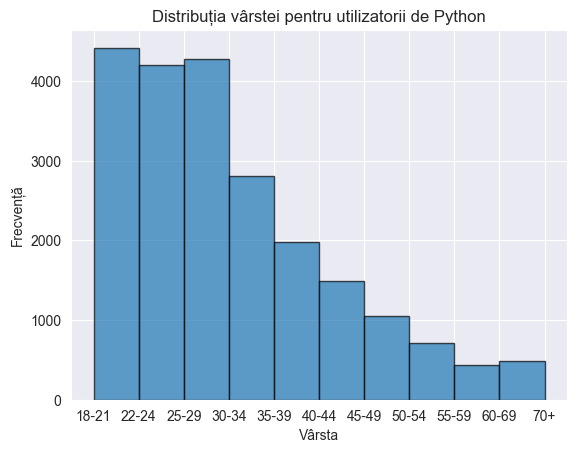

In [10]:
# ex 9 distributia respondentilor care programeaza in Python pe categorii de varsta
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/surveyDataSience.csv', low_memory = False)

df = df.drop(0)

distributia_varsta_python = df[(df["Q7_Part_1"] == "Python")]["Q1"]
distributia_varsta_python = distributia_varsta_python.sort_values()
plt.hist(distributia_varsta_python, edgecolor='black', alpha=0.7)

plt.xlabel('Vârsta')
plt.ylabel('Frecvență')
plt.title('Distribuția vârstei pentru utilizatorii de Python')

plt.show()



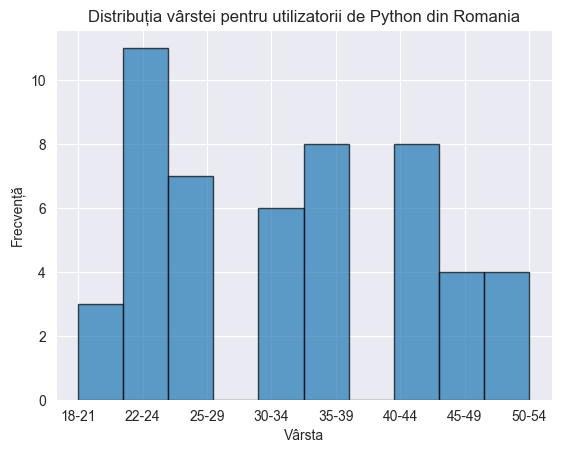

In [9]:
# ex 10 distributia respondentilor din Romania care programeaza in Python pe categorii de varsta
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/surveyDataSience.csv', low_memory = False)

df = df.drop(0)

distributia_varsta_python_romania = df[(df["Q7_Part_1"] == "Python") & (df["Q3"] == "Romania")]["Q1"]
distributia_varsta_python_romania = distributia_varsta_python_romania.sort_values()

plt.hist(distributia_varsta_python_romania, edgecolor='black', alpha=0.7)

plt.xlabel('Vârsta')
plt.ylabel('Frecvență')
plt.title('Distribuția vârstei pentru utilizatorii de Python din Romania')

plt.show()


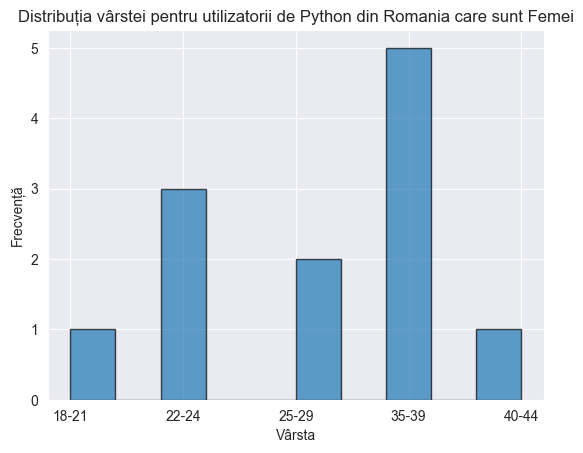

In [11]:
# ex 11 distributia respondentilor femei din Romania care programeaza in Python pe categorii de varsta

distributia_varsta_python_romania_femei = df[(df["Q7_Part_1"] == "Python") & (df["Q3"] == "Romania") & (df["Q2"] == "Woman")]["Q1"]
distributia_varsta_python_romania_femei = distributia_varsta_python_romania_femei.sort_values()

plt.hist(distributia_varsta_python_romania_femei, edgecolor='black', alpha=0.7)

plt.xlabel('Vârsta')
plt.ylabel('Frecvență')
plt.title('Distribuția vârstei pentru utilizatorii de Python din Romania care sunt Femei')

plt.show()


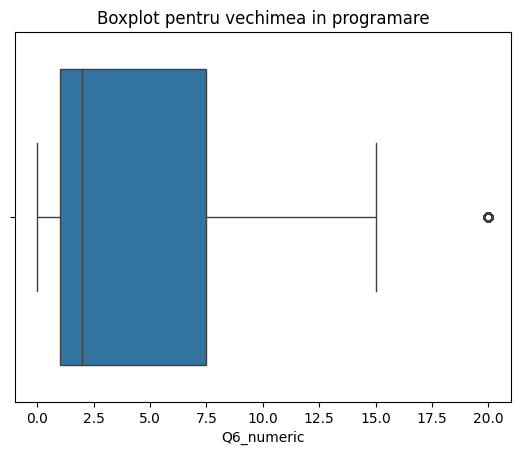

2        20.0
4        20.0
17       20.0
24       20.0
70       20.0
         ... 
25863    20.0
25888    20.0
25911    20.0
25925    20.0
25964    20.0
Name: Q6_numeric, Length: 1860, dtype: float64


In [93]:
# ex 12 respondentii care pot fi considerati "outlieri" din punct de vedere al vechimii in programare (puteti folositi un boxplot pentru a identifica aceste valori)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Crearea unui boxplot
sns.boxplot(x=df_vechime["Q6_numeric"])

# Afisarea graficului
plt.title('Boxplot pentru vechimea in programare')
plt.show()

# Calcularea IQR-ului pentru identificarea outlierilor
Q1 = df_vechime["Q6_numeric"].quantile(0.25)
Q3 = df_vechime["Q6_numeric"].quantile(0.75)
IQR = Q3 - Q1

# Definirea limitelor pentru outlieri
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identificarea outlierilor
outliers_lower = df_vechime[df_vechime["Q6_numeric"] < lower_bound]
outliers_upper = df_vechime[df_vechime["Q6_numeric"] > upper_bound]

# Concatenarea celor două DataFrame-uri
outliers = pd.concat([outliers_lower, outliers_upper])

# Afisarea respondentilor care sunt outlieri
print(outliers["Q6_numeric"])



1        0.375
2        1.000
3        0.100
4        1.000
5        0.050
         ...  
25969    0.100
25970    0.100
25971    0.000
25972    0.375
25973    0.000
Name: normalizare, Length: 25973, dtype: float64


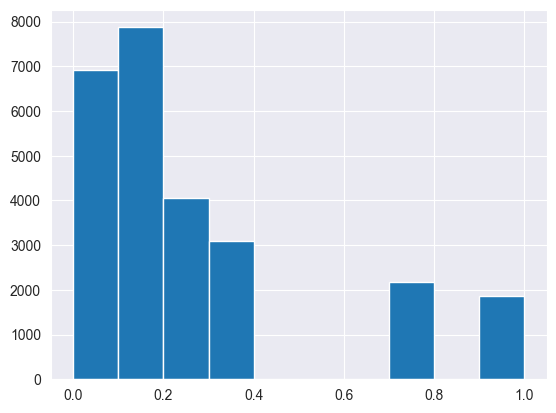

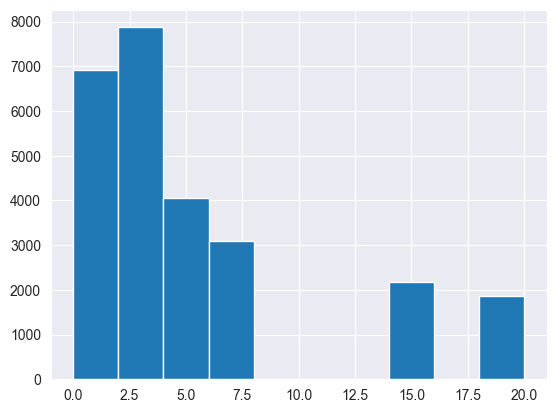

In [9]:
# NORMALIZARE durata anilor de studii universitare, vechimea in programare Q6

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/surveyDataSience.csv', low_memory = False)

df = df.drop(0)

X_min = df_vechime["Q6_numeric"].min()
X_max = df_vechime["Q6_numeric"].max()

def normalize(value):
    return (value - X_min) / (X_max - X_min)

df_vechime["normalizare"] = df_vechime["Q6_numeric"].apply(normalize)
print(df_vechime["normalizare"])

# X_norm = (X - X_min)/(X_max - X_min)

plt.hist(df_vechime["normalizare"])

plt.show()

plt.hist(df_vechime["Q6_numeric"])

plt.show()
